In [1]:
import torch
from torch import nn

torch.__version__

'2.7.0'

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

We need our custom data, let's download it


In [11]:
import requests
from pathlib import Path
import zipfile

# Setup data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"
zip_path = data_path / "pizza_steak_sushi.zip"

# Check if the folder exists AND actually contains the 'train' directory
if image_path.is_dir() and (image_path / "train").exists():
    print(f"{image_path} directory already exists and contains data. Skipping...")
else:
    print(f"Directory is missing or empty. Setting up...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download the zip file
    print("Downloading pizza, steak, sushi data...")
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    
    with open(zip_path, "wb") as f:
        f.write(request.content)

    # Unzip the data
    print("Unzipping pizza, steak, sushi data...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(image_path)
        
    print("Done!")

# Verification
extracted_items = list(image_path.iterdir())
print(f"Contents of {image_path}: {extracted_items}")

Directory is missing or empty. Setting up...
Unzipping pizza, steak, sushi data...
Done!
Contents of data/pizza_steak_sushi: [PosixPath('data/pizza_steak_sushi/test'), PosixPath('data/pizza_steak_sushi/train')]


Before starting a project or building any kind of model, it's important to know what data you're working with.

In our case, we have images of pizza, steak and sushi in standard image classification format.

In [12]:
import os 
def walk_through_dir(dir_path):
    """
    Walks through dir_path returning its contents.
    Args:
        dir_path (str or pathlib.Path): target directory
    
    Returns:
        A print out of:
            number of subdirectories in dir_path
            number of images (files) in each subdirectory
            name of each subdirectory
    """
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in {dir_path}")

walk_through_dir(image_path)


There are 2 directories and 0 images in data/pizza_steak_sushi
There are 3 directories and 0 images in data/pizza_steak_sushi
There are 0 directories and 19 images in data/pizza_steak_sushi
There are 0 directories and 31 images in data/pizza_steak_sushi
There are 0 directories and 25 images in data/pizza_steak_sushi
There are 3 directories and 0 images in data/pizza_steak_sushi
There are 0 directories and 75 images in data/pizza_steak_sushi
There are 0 directories and 72 images in data/pizza_steak_sushi
There are 0 directories and 78 images in data/pizza_steak_sushi


In [13]:
# Setup train and test path
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

Random image path: data/pizza_steak_sushi/test/pizza/2236338.jpg
Image class: pizza
Image height: 512
Image width: 512


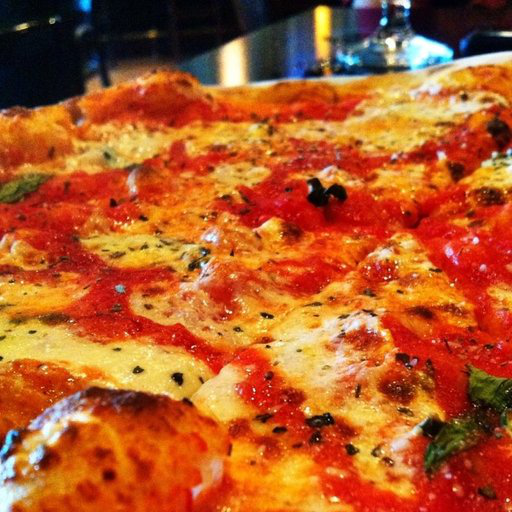

In [14]:
# Vediamo che immagini abbiamo
from PIL import Image
import random

random.seed(42)

# Prendiamo i path di tutte le immagini
image_path_list = list(image_path.glob("*/*/*.jpg"))

# Scegliamone una a caso
random_image_path = random.choice(image_path_list)

# Otteniamo la classe dell'immagine 
# (the image class is the name of the directory where the image is stored)
image_class = random_image_path.parent.stem

img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}") 
print(f"Image width: {img.width}")
img

Before we can use our image data with PyTorch we need to:

Turn it into tensors (numerical representations of our images).

Turn it into a `torch.utils.data.Dataset` and subsequently a `torch.utils.data`.

DataLoader, we'll call these Dataset and DataLoader for short.

There are several different kinds of pre-built datasets and dataset loaders for PyTorch, depending on the problem you're working on.





| Problem space | Pre-built Datasets and Functions |
| :--- | :--- |
| **Vision** | [`torchvision.datasets`](https://pytorch.org/vision/stable/datasets.html) |
| **Audio** | [`torchaudio.datasets`](https://pytorch.org/audio/stable/datasets.html) |
| **Text** | [`torchtext.datasets`](https://pytorch.org/text/stable/datasets.html) |
| **Recommendation system** | [`torchrec.datasets`](https://pytorch.org/torchrec/torchrec.datasets.html) |

Since we're working with a **vision** problem, we'll be looking at `torchvision`.datasets for our data loading functions as well as `torchvision.transforms` for preparing our data.


In [19]:
import torch
from torch.utils.data import  DataLoader
from torchvision import datasets, transforms

# We need to convert our image into tensor before we use them

# Write transform for our images
data_transform = transforms.Compose([
    # Resize the images to 64x64
    transforms.Resize(size=(64,64)),
    # Flips the image randomly on the horizontal
    transforms.RandomHorizontalFlip(p=0.5), # probability of flip
    # Transform the image into a torch.tensor
    transforms.ToTensor()

])


Now we've got a composition of transforms, let's write a function to try them out on various images.

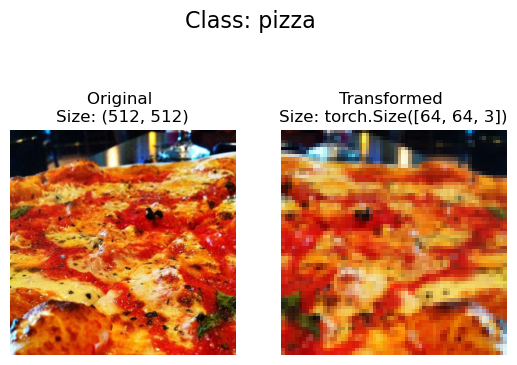

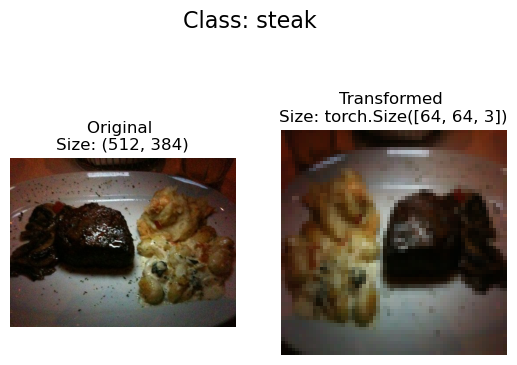

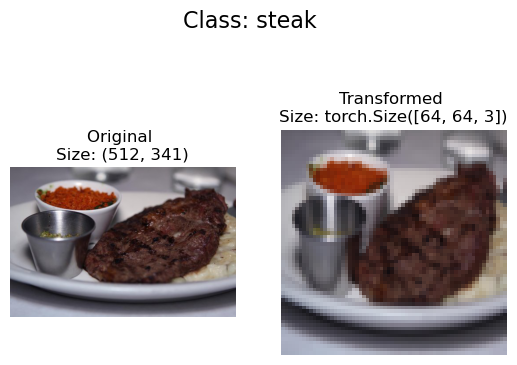

In [20]:
import matplotlib.pyplot as plt

def plot_transformed_images(image_paths, transform, n=3, seed=42):
    """
    Plot a series of random images from image_paths.

    Will open n image paths from image_paths, transform them with transform and plot them side by side.

    Args:
        image_paths (list) : List of target image paths.
        transform (PyTorch Transforms) : Transforms to apply to the images.
        n (int, optional) : Number of images to plot.
        seed (int, optinal) : Random seed for the random generator. 

    """

    random.seed(seed)
    random_image_paths = random.sample(image_paths, n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1,2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Transform and plot image 
            # Note: permute() will change shape of image to suit matplotlib 
            # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            transformed_image = transform(f).permute(1,2,0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, transform=data_transform)

Alright, time to turn our image data into a Dataset capable of being used with PyTorch.

Since our data is in standard image classification format, we can use the class `torchvision.datasets`.

*ImageFolder*.

In [21]:
from torchvision import datasets

train_data = datasets.ImageFolder(root=train_dir, transform=data_transform, target_transform=None)

test_data = datasets.ImageFolder(root=test_dir, transform=data_transform, target_transform=None)

print(f"Train data: \n{train_data}\nTest data: \n{test_data}")

Train data: 
Dataset ImageFolder
    Number of datapoints: 225
    Root location: data/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
Test data: 
Dataset ImageFolder
    Number of datapoints: 75
    Root location: data/pizza_steak_sushi/test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


Ispezioniamo le classi 

In [23]:
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [24]:
# Can also get class names as a dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [25]:
# check the lengths
len(train_data), len(test_data)

(225, 75)

In [27]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0863],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0706],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0196,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.09

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Image permute shape: torch.Size([64, 64, 3]) -> [height, width, color_channels]


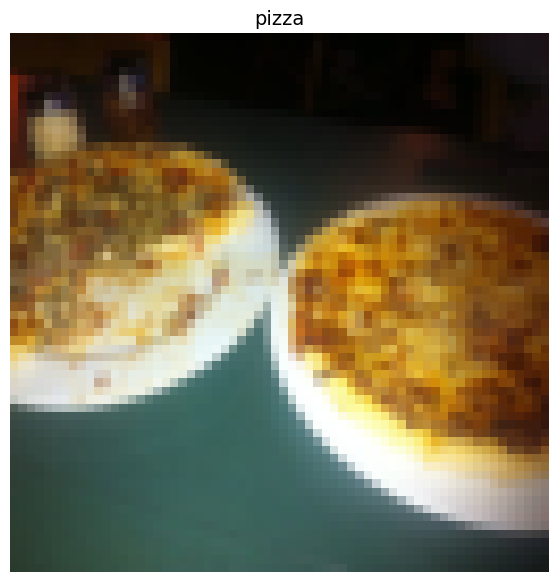

In [28]:
# Rearrange the order of dimensions
img_permute = img.permute(1, 2, 0)

# Print out different shapes (before and after permute)
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img.permute(1, 2, 0))
plt.axis("off")
plt.title(class_names[label], fontsize=14);

In [29]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=1,
    num_workers=1,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=1,
    num_workers=1,
    shuffle=False
)

In [30]:
img, label = next(iter(train_loader))

print(f"Img shape: {img.shape} -> [batch_size, channel, height, width]")
print(f"Image label shape: {label.shape}")

Img shape: torch.Size([1, 3, 64, 64]) -> [batch_size, channel, height, width]
Image label shape: torch.Size([1])
